### Step 1: Install Bioinformatics Dependencies

To analyze RNA-seq data, we need specialized bioinformatics tools that aren't pre-installed in Google Colab.
* **SRA Toolkit:** Used to fetch raw sequencing data directly from public databases (NCBI).
* **STAR:** A highly efficient splice-aware aligner that maps our raw RNA reads to the human reference genome.
* **Subread (featureCounts):** A tool to count how many reads mapped to each gene.
* **FastQC:** A quality control tool to check the health and quality of our sequencing data.

In [3]:
!sudo dpkg --configure -a
!sudo apt-get update
!sudo DEBIAN_FRONTEND=noninteractive apt-get install -yq -o Dpkg::Options::="--force-confdef" -o Dpkg::Options::="--force-confold" sra-toolkit fastqc subread

# Compile and install STAR aligner
!wget -O 2.7.10b.tar.gz https://github.com/alexdobin/STAR/archive/2.7.10b.tar.gz
!tar -xzf 2.7.10b.tar.gz
!cd STAR-2.7.10b/source && make STAR
!cp STAR-2.7.10b/bin/Linux_x86_64/STAR /usr/local/bin/

Setting up med-config (3.8.1) ...
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79.)
debconf: falling back to frontend: Readline
Configuring med-config
----------------------

Please select, among the whole system user list, users who should get a Debian
Med user menu.

  1. ubuntu (Ubuntu)

(Enter the items or ranges you want to select, separated by spaces.)

Debian Med users: 
dpkg: error processing package med-config (--configure):
 installed med-config package post-installation script subprocess returned error exit status 30
Errors were encountered while processing:
 med-config
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 https://r2u.stat.illinois.edu/ubuntu noble InRel

### Step 2: Download Reference Genome (hg38)

RNA-sequencing produces millions of short nucleotide sequences (reads). To make sense of them, we need a map of the genome.
* **FASTA file (`hg38.fa.gz`):** The actual DNA sequence of the human genome.
* **GTF file (`hg38.gtf.gz`):** The annotation file that tells us exactly where genes, exons, and transcripts are located on that DNA sequence.

In [4]:
!mkdir -p /content/reference
# Download FASTA
!wget ftp://ftp.ensembl.org/pub/release-109/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz -O /content/reference/hg38.fa.gz
# Download GTF
!wget ftp://ftp.ensembl.org/pub/release-109/gtf/homo_sapiens/Homo_sapiens.GRCh38.109.gtf.gz -O /content/reference/hg38.gtf.gz

# Unzip the files
!gunzip /content/reference/hg38.fa.gz
!gunzip /content/reference/hg38.gtf.gz

--2026-10-18 08:31:10--  ftp://ftp.ensembl.org/pub/release-109/fasta/homo_sapiens/dna/Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz
           => ‘/content/reference/hg38.fa.gz’
Resolving ftp.ensembl.org (ftp.ensembl.org)... 193.62.193.169
Connecting to ftp.ensembl.org (ftp.ensembl.org)|193.62.193.169|:21... connected.
Logging in as anonymous ... Logged in!
==> SYST ... done.    ==> PWD ... done.
==> TYPE I ... done.  ==> CWD (1) /pub/release-109/fasta/homo_sapiens/dna ... done.
==> SIZE Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz ... 881211416
==> PASV ... done.    ==> RETR Homo_sapiens.GRCh38.dna.primary_assembly.fa.gz ... done.
Length: 881211416 (840M) (unauthoritative)

Homo_sapiens.GRCh38 100%[===================>] 840.39M   815KB/s    in 8m 8s   

2026-10-18 08:39:19 (1.72 MB/s) - ‘/content/reference/hg38.fa.gz’ saved [881211416]

--2026-10-18 08:39:19--  ftp://ftp.ensembl.org/pub/release-109/gtf/homo_sapiens/Homo_sapiens.GRCh38.109.gtf.gz
           => ‘/content/reference/hg

### Step 3: Build STAR Genome Index

Mapping millions of short reads directly to a 3-billion-letter human genome on the fly is computationally heavy. STAR creates a compressed "index" of the genome and known splice junctions. This upfront cost makes the actual alignment step extremely fast and accurate.
*Note: This step requires ~30-40GB of RAM.*

In [5]:
!mkdir -p /content/reference/star_index
!STAR --runMode genomeGenerate \
  --runThreadN 8 \
  --genomeDir /content/reference/star_index \
  --genomeFastaFiles /content/reference/hg38.fa \
  --sjdbGTFfile /content/reference/hg38.gtf \
  --sjdbOverhang 99

	STAR --runMode genomeGenerate --runThreadN 8 --genomeDir /content/reference/star_index --genomeFastaFiles /content/reference/hg38.fa --sjdbGTFfile /content/reference/hg38.gtf --sjdbOverhang 99
	STAR version: 2.7.10b   compiled: 2022-11-01T09:53:26-04:00 :/home/dobin/data/STAR/STARcode/STAR.master/source
Oct 18 08:58:59 ..... started STAR run
Oct 18 08:58:59 ... starting to generate Genome files
Oct 18 08:59:36 ..... processing annotations GTF
Oct 18 08:59:53 ... starting to sort Suffix Array. This may take a long time...
Oct 18 09:00:09 ... sorting Suffix Array chunks and saving them to disk...
Oct 18 09:42:12 ... loading chunks from disk, packing SA...
Oct 18 09:45:32 ... finished generating suffix array
Oct 18 09:45:32 ... generating Suffix Array index
Oct 18 09:50:31 ... completed Suffix Array index
Oct 18 09:50:32 ..... inserting junctions into the genome indices
Oct 18 09:55:06 ... writing Genome to disk ...
Oct 18 09:55:13 ... writing Suffix Array to disk ...
Oct 18 09:56:24 ...

### Step 4: Download Raw Sequencing Data

We need the raw experimental data to process. We query the NCBI Sequence Read Archive (SRA) for our specific project (`DRA015121`). The `fasterq-dump` tool downloads and converts the proprietary SRA format into standard FASTQ files, which contain the raw sequence reads and their quality scores.

In [6]:
import os
import pandas as pd
import urllib.request
import xml.etree.ElementTree as ET
from io import StringIO

project_id = "DRA015121"
print(f"Querying NCBI for project {project_id}...")

# 1. Search for SRA IDs associated with the project
search_url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi?db=sra&term={project_id}"
response = urllib.request.urlopen(search_url).read()
root = ET.fromstring(response)
id_list = [id_elem.text for id_elem in root.find("IdList").findall("Id")]

if not id_list:
    print("Error: No SRA records found for this project.")
else:
    # 2. Fetch RunInfo CSV using the IDs
    ids_str = ",".join(id_list)
    fetch_url = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=sra&id={ids_str}&rettype=runinfo&retmode=csv"
    runinfo_data = urllib.request.urlopen(fetch_url).read().decode('utf-8')

    # The fetched CSV might not have standard headers, so we read without headers and pick the first column
    runinfo_df = pd.read_csv(StringIO(runinfo_data), header=None)
    run_accessions = runinfo_df[0].dropna().tolist()
    print(f"Found {len(run_accessions)} Run Accessions. First 5: {run_accessions[:5]}")

    # 3. Download the data using SRA Toolkit
    !mkdir -p /content/raw_data

    # NOTE: Downloading all files can take hours and exceed disk space.
    for run in run_accessions[:5]:
        print(f"\n--- Downloading {run} ---")
        os.system(f"prefetch {run}")
        os.system(f"fasterq-dump {run} --split-files --outdir /content/raw_data/")
        print(f"Finished downloading {run}")


Querying NCBI for project DRA015121...
Found 20 Run Accessions. First 5: ['DRR416925', 'DRR416926', 'DRR416927', 'DRR416928', 'DRR416929']

--- Downloading DRR416925 ---
Finished downloading DRR416925

--- Downloading DRR416926 ---
Finished downloading DRR416926

--- Downloading DRR416927 ---
Finished downloading DRR416927

--- Downloading DRR416928 ---
Finished downloading DRR416928

--- Downloading DRR416929 ---
Finished downloading DRR416929


### Step 4.5: Quality Control with FastQC

Sequencing machines are not perfect. We run FastQC to generate reports checking for adapter contamination, poor quality bases, and abnormal GC content. Ensuring our reads are high-quality gives us confidence in our downstream gene expression results.

In [7]:
!mkdir -p /content/fastqc_results

# Run FastQC on all fastq files directly using bash magic to see the live output
!fastqc -t 8 -o /content/fastqc_results /content/raw_data/*.fastq

print("FastQC analysis complete. You can find the HTML reports in /content/fastqc_results")

[0.020s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.020s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
null
null
Started analysis of DRR416925_1.fastq
null
null
null
null
null
null
null
null
Started analysis of DRR416925_2.fastq
Started analysis of DRR416926_1.fastq
Started analysis of DRR416926_2.fastq
Started analysis of DRR416927_1.fastq
Started analysis of DRR416927_2.fastq
Started analysis of DRR416928_1.fastq
Started analysis of DRR416928_2.fastq
Approx 5% complete for DRR416925_1.fastq
Approx 5% complete for DRR416925_2.fastq
Approx 5% complete for DRR416926_1.fastq
Approx 5% complete for DRR416926_2.fastq
Approx 5% complete for DRR416927_2.fastq
Approx 5% complete for DRR416928_1.fastq
Approx 5% complete for DRR416927_1.fastq
Approx 5% complete for DRR4169

### Step 5: Alignment and Quantification

This is the core of the pipeline where raw data is converted into quantifiable gene expression.
1. **Alignment (STAR):** Takes our short RNA reads and matches them to the human genome, outputting a `.bam` file.
2. **Quantification (featureCounts):** Looks at the `.bam` alignments and our `.gtf` annotation file, counting exactly how many reads fall within each gene. This yields a matrix of counts.
*We also aggressively clean up large temporary files (`.fastq`, `.bam`) to prevent Google Colab from running out of disk space.*

In [9]:
%%bash
mkdir -p /content/aligned_data

# Exit immediately if a command exits with a non-zero status
set -e

shopt -s nullglob
fastq_files=(/content/raw_data/*_1.fastq)

if [ ${#fastq_files[@]} -eq 0 ]; then
    echo "No FASTQ files found in /content/raw_data/. Did the download complete successfully?"
    exit 0
fi

for f in "${fastq_files[@]}"; do
    run=$(basename "$f" _1.fastq)
    echo -e "\n--- Aligning $run ---"

    STAR --runMode alignReads \
         --runThreadN 8 \
         --genomeDir /content/reference/star_index \
         --readFilesIn /content/raw_data/${run}_1.fastq /content/raw_data/${run}_2.fastq \
         --outFileNamePrefix /content/aligned_data/${run}_ \
         --outSAMtype BAM SortedByCoordinate

    echo "Successfully aligned $run. Cleaning up raw files..."
    rm -rf /content/${run} /root/ncbi/public/sra/${run}.sra
    rm -f /content/raw_data/${run}_1.fastq /content/raw_data/${run}_2.fastq
done

echo -e "\n--- Running featureCounts ---"
featureCounts -T 8 -p -a /content/reference/hg38.gtf \
              -o /content/gene_counts.txt \
              /content/aligned_data/*_Aligned.sortedByCoord.out.bam

echo "Quantification complete. Cleaning up BAM files to save space..."
rm -rf /content/aligned_data/
echo "All done!"



--- Aligning DRR416925 ---
	STAR --runMode alignReads --runThreadN 8 --genomeDir /content/reference/star_index --readFilesIn /content/raw_data/DRR416925_1.fastq /content/raw_data/DRR416925_2.fastq --outFileNamePrefix /content/aligned_data/DRR416925_ --outSAMtype BAM SortedByCoordinate
	STAR version: 2.7.10b   compiled: 2022-11-01T09:53:26-04:00 :/home/dobin/data/STAR/STARcode/STAR.master/source
Oct 18 11:01:49 ..... started STAR run
Oct 18 11:01:49 ..... loading genome
Oct 18 11:04:15 ..... started mapping
Oct 18 11:10:20 ..... finished mapping
Oct 18 11:10:23 ..... started sorting BAM
Oct 18 11:11:55 ..... finished successfully
Successfully aligned DRR416925. Cleaning up raw files...

--- Aligning DRR416926 ---
	STAR --runMode alignReads --runThreadN 8 --genomeDir /content/reference/star_index --readFilesIn /content/raw_data/DRR416926_1.fastq /content/raw_data/DRR416926_2.fastq --outFileNamePrefix /content/aligned_data/DRR416926_ --outSAMtype BAM SortedByCoordinate
	STAR version: 2.7


        ==========     _____ _    _ ____  _____  ______          _____  
        =====         / ____| |  | |  _ \|  __ \|  ____|   /\   |  __ \ 
          =====      | (___ | |  | | |_) | |__) | |__     /  \  | |  | |
            ====      \___ \| |  | |  _ <|  _  /|  __|   / /\ \ | |  | |
              ====    ____) | |__| | |_) | | \ \| |____ / ____ \| |__| |
        ==========   |_____/ \____/|____/|_|  \_\______/_/    \_\_____/
	  v2.0.6

//========================== featureCounts setting ===========================\\
||                                                                            ||
||             Input files : 5 BAM files                                      ||
||                                                                            ||
||                           DRR416925_Aligned.sortedByCoord.out.bam          ||
||                           DRR416926_Aligned.sortedByCoord.out.bam          ||
||                           DRR416927_Aligned.sortedByCoord.out.

### Step 6: Load Gene Counts into Pandas

With the computationally heavy bioinformatics tools finished, we now transition into standard Python Data Science. We load the `gene_counts.txt` matrix into a Pandas DataFrame so we can easily filter, plot, and analyze the gene expression levels across all our samples.

In [11]:
import pandas as pd
import os

print("--- Loading Gene Counts ---")
if os.path.exists('/content/gene_counts.txt'):
    # featureCounts output has some metadata lines at the top, we skip the first row (command info)
    counts_df = pd.read_csv('/content/gene_counts.txt', sep='\t', comment='#')

    # Clean up column names (remove the path and file extensions)
    new_columns = []
    for col in counts_df.columns:
        if 'Aligned.sortedByCoord.out.bam' in col:
            run_id = os.path.basename(col).split('_')[0]
            new_columns.append(run_id)
        else:
            new_columns.append(col)
    counts_df.columns = new_columns

    display(counts_df.head())
else:
    print("Counts file not found. Please check the featureCounts logs above for errors.")


--- Loading Gene Counts ---


,Geneid,Chr,Start,End,Strand,Length,DRR416925,DRR416926,DRR416927,DRR416928,DRR416929
0,ENSG00000160072,1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;...,1471765;1471784;1477274;1477274;1478026;147864...,1472089;1472089;1477350;1477350;1478745;147874...,+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;...,7686,1195,1617,2199,1906,2051
1,ENSG00000279928,1;1;1;1;1,182696;183132;183494;183740;183981,182746;183216;183571;183901;184174,+;+;+;+;+,570,0,0,0,0,0
2,ENSG00000228037,1;1;1,2581560;2583370;2584125,2581650;2583495;2584533,+;+;+,626,0,0,0,0,2
3,ENSG00000142611,1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;1;...,3069168;3069183;3069197;3069203;3069211;318612...,3069296;3069296;3069296;3069296;3069296;318647...,+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;+;...,9767,2,4,4,0,0
4,ENSG00000284616,1;1;1;1,5301928;5303328;5304401;5306942,5302004;5303393;5305029;5307394,-;-;-;-,1225,0,0,0,0,0


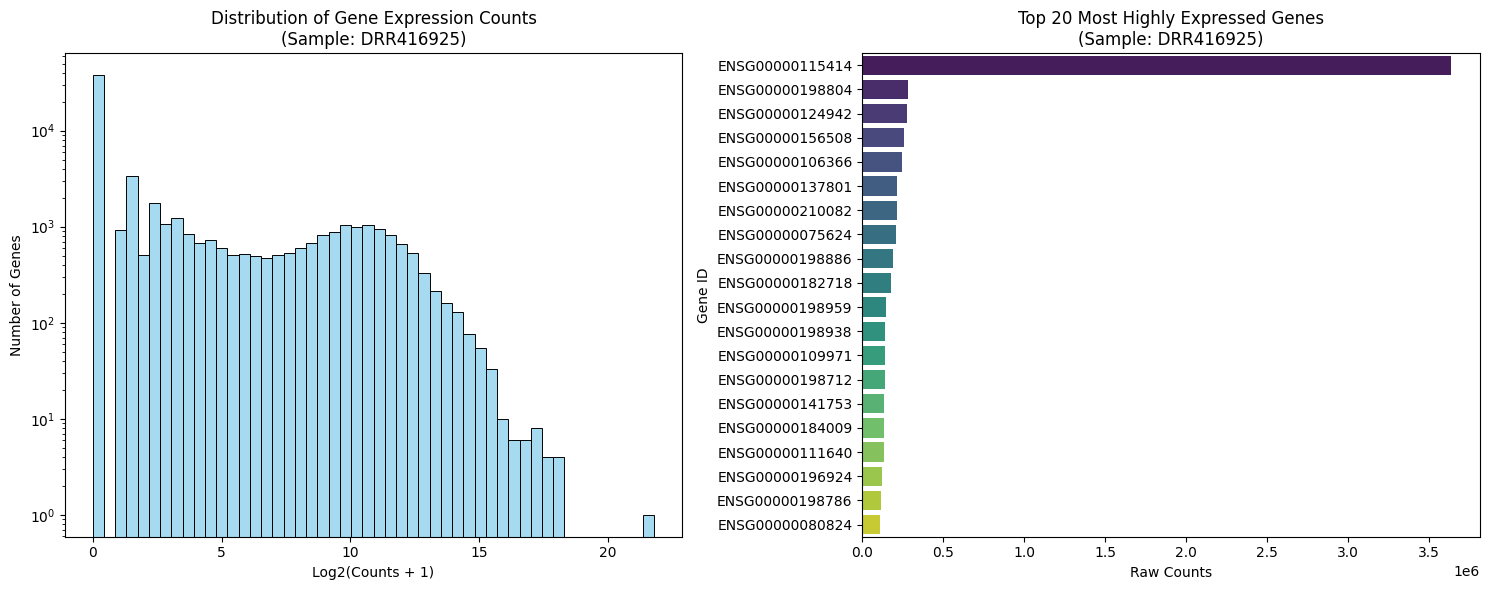

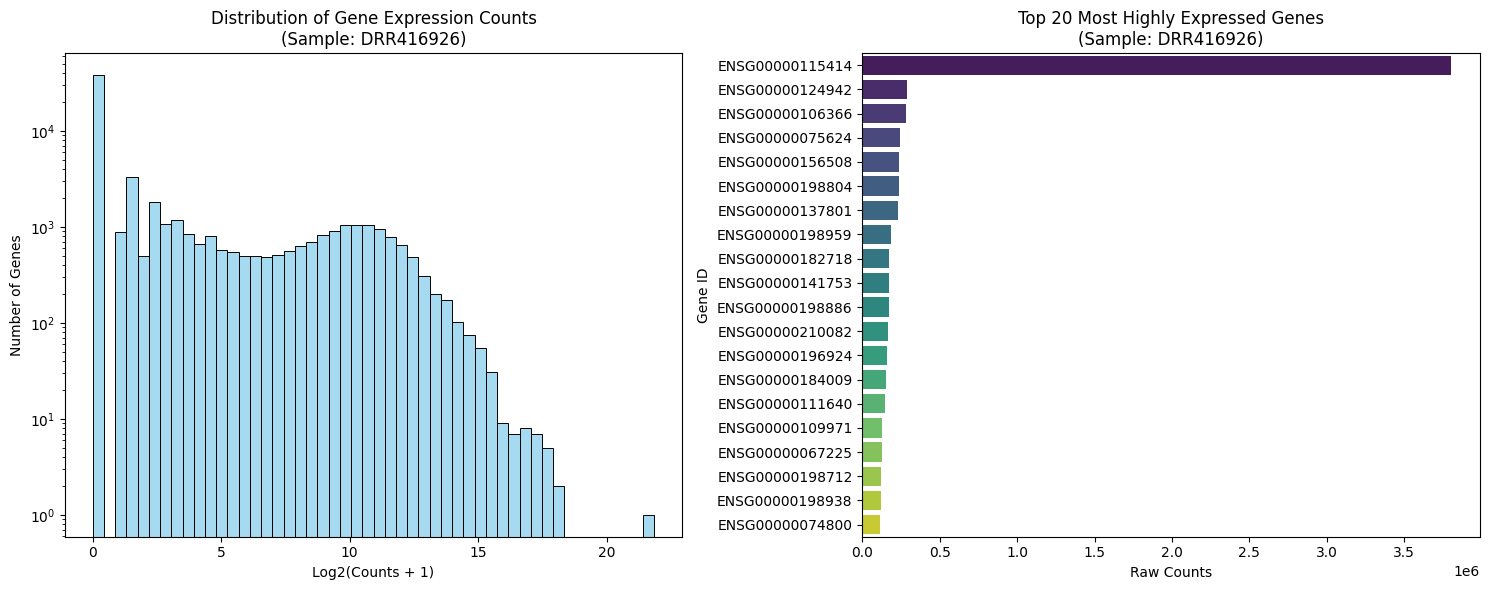

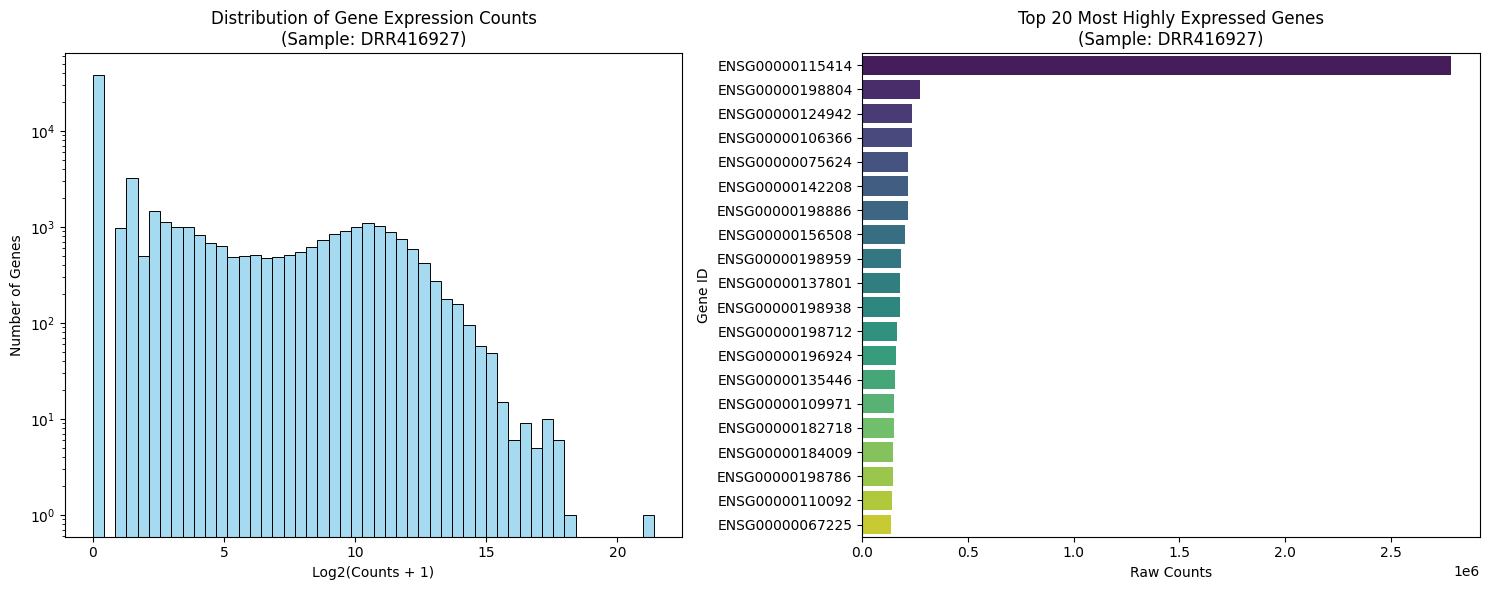

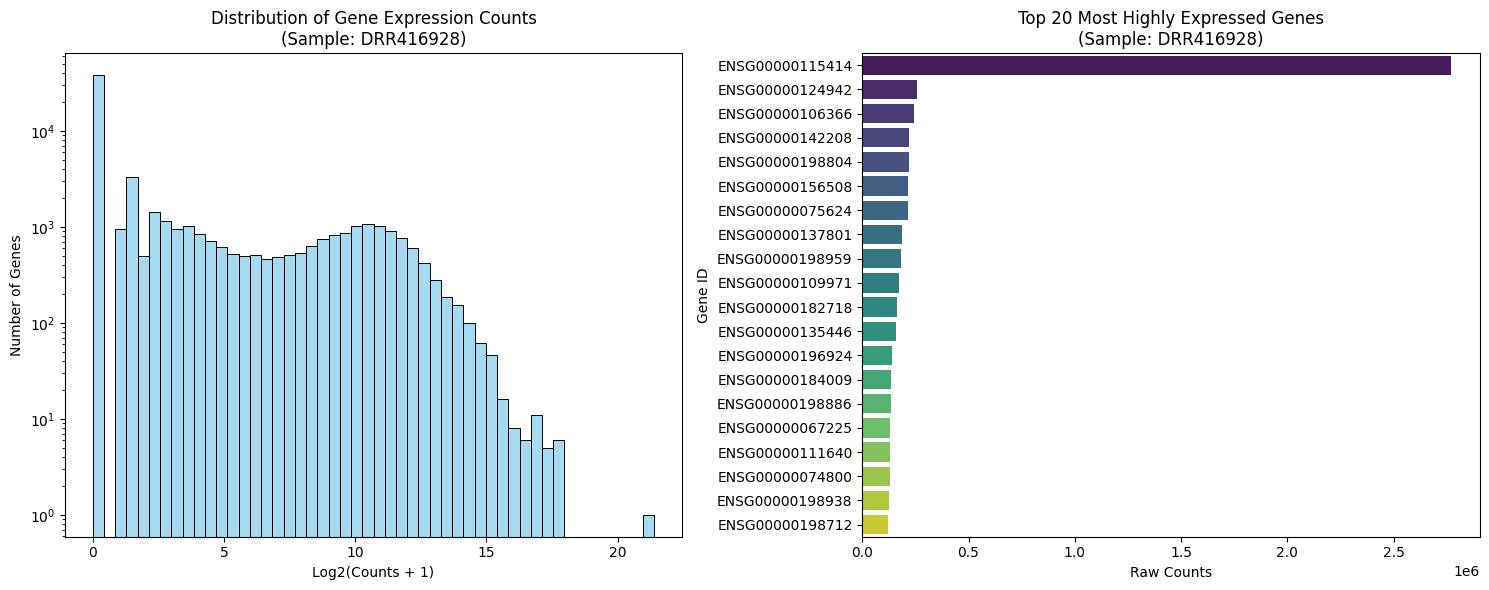

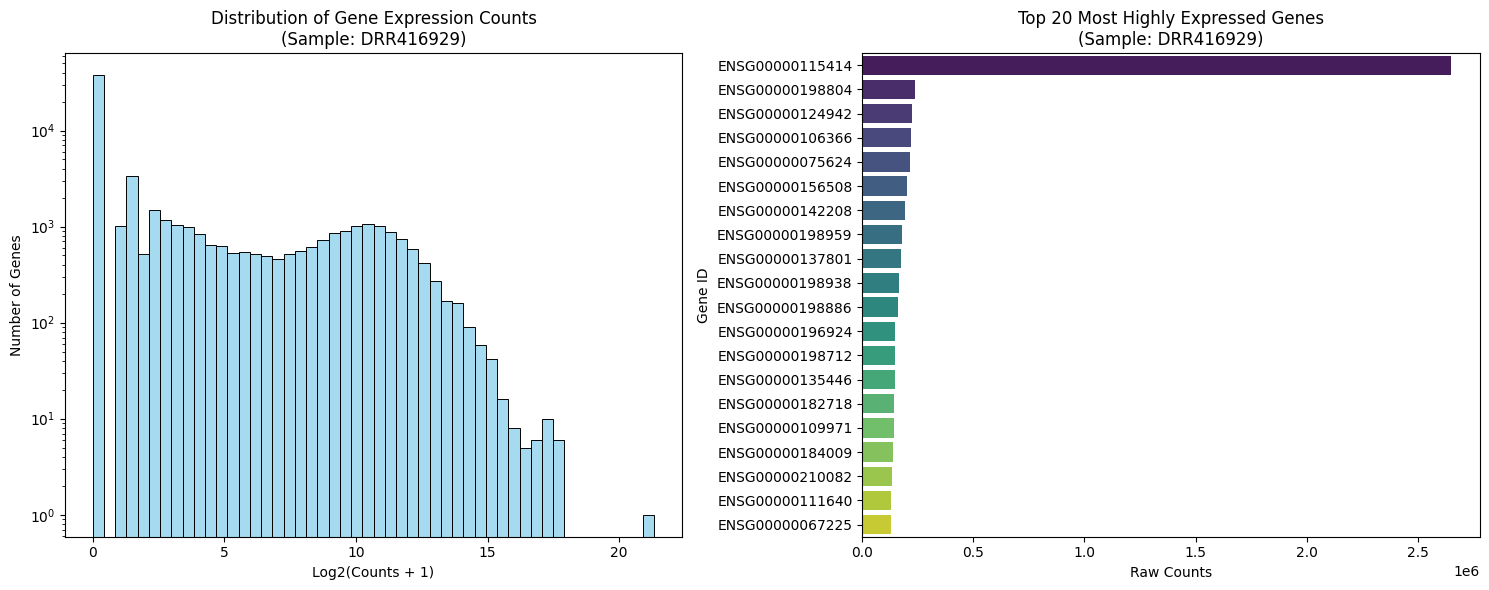

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

if 'counts_df' in locals():
    # Get the list of sample columns (skip the first 6 which are gene metadata)
    sample_cols = counts_df.columns[6:]

    for sample in sample_cols:
        # Create a copy and rename the column for easier plotting
        df_plot = counts_df[['Geneid', sample]].copy()
        df_plot.rename(columns={sample: 'Counts'}, inplace=True)

        # Set up the figure
        plt.figure(figsize=(15, 6))

        # Plot 1: Distribution of counts (log2 transformed to handle large ranges)
        plt.subplot(1, 2, 1)
        # Adding 1 to avoid log(0)
        log_counts = np.log2(df_plot['Counts'] + 1)
        sns.histplot(log_counts, bins=50, color='skyblue', kde=False)
        plt.title(f'Distribution of Gene Expression Counts\n(Sample: {sample})')
        plt.xlabel('Log2(Counts + 1)')
        plt.ylabel('Number of Genes')
        plt.yscale('log') # Use log scale for Y as well to see the tail clearly

        # Plot 2: Top 20 highest expressed genes
        plt.subplot(1, 2, 2)
        top_20 = df_plot.sort_values(by='Counts', ascending=False).head(20)
        sns.barplot(x='Counts', y='Geneid', data=top_20, hue='Geneid', palette='viridis', legend=False)
        plt.title(f'Top 20 Most Highly Expressed Genes\n(Sample: {sample})')
        plt.xlabel('Raw Counts')
        plt.ylabel('Gene ID')

        plt.tight_layout()
        plt.show()
else:
    print("Cannot plot: 'counts_df' is not defined. Please ensure Step 5 and the loading step completed successfully.")

In [12]:
from google.colab import files

# Save the counts_df DataFrame to a CSV file
csv_filename = 'counts_df.csv'
counts_df.to_csv(csv_filename, index=False)

# Download the CSV file to your local machine
files.download(csv_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
if 'counts_df' in locals():
    # The first 6 columns in featureCounts output are always metadata.
    # Sample columns start at index 6.
    sample_cols = list(counts_df.columns[6:])

    # Select only Geneid, Length, and the sample columns
    final_counts_df = counts_df[['Geneid', 'Length'] + sample_cols].copy()

    print("Successfully created final_counts_df!")
    display(final_counts_df.head())
else:
    print("Error: 'counts_df' is not defined. Please run the cell that loads the counts matrix first.")

Successfully created final_counts_df!


,Geneid,Length,DRR416925,DRR416926,DRR416927,DRR416928,DRR416929
0,ENSG00000160072,7686,1195,1617,2199,1906,2051
1,ENSG00000279928,570,0,0,0,0,0
2,ENSG00000228037,626,0,0,0,0,2
3,ENSG00000142611,9767,2,4,4,0,0
4,ENSG00000284616,1225,0,0,0,0,0


In [15]:
from google.colab import files

if 'final_counts_df' in locals():
    csv_filename = 'final_counts_df.csv'
    final_counts_df.to_csv(csv_filename, index=False)
    print(f"Downloading {csv_filename}...")
    files.download(csv_filename)
else:
    print("Error: 'final_counts_df' is not defined.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>